In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [238]:
df=pd.read_csv('../dataset/Mall_Customers.csv')

In [239]:
df.head(5)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [240]:
df.info()
# each col and its datatype with no of null values

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [241]:
# we see gender named as genre rename it 

df.rename(columns={'Genre':'Gender'},inplace=True)

In [242]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [243]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [244]:
# we can see there are no nulls from df.info()

In [245]:
# check duplicate records

df.duplicated().sum()
# we see no duplicates as well

np.int64(0)

In [246]:
# also rename annual income and spending score
df.rename(columns={'Annual Income (k$)':'Annual_Income','Spending Score (1-100)':'Spending_Score'},inplace=True)

In [247]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      200 non-null    int64
 1   Gender          200 non-null    str  
 2   Age             200 non-null    int64
 3   Annual_Income   200 non-null    int64
 4   Spending_Score  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


# EDA

In [248]:
# numerical cols --> Age,Annual Income,Spending Score
# categorical cols --> Gender

# the customerid col is of no use except for unique cust identification which has no use in identifying the clusters

### EDA for numerical cols

### univariate analysis

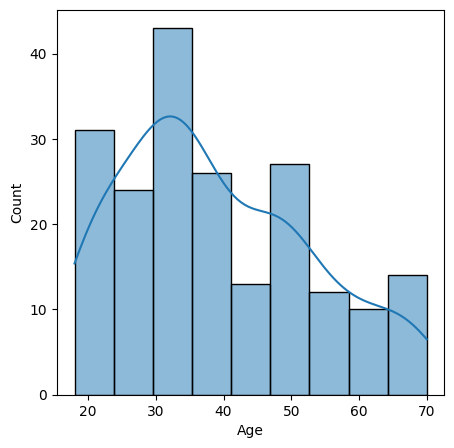

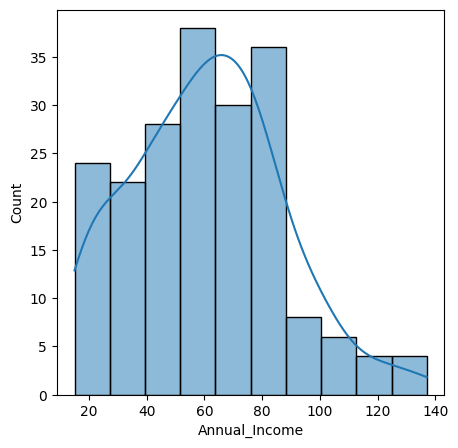

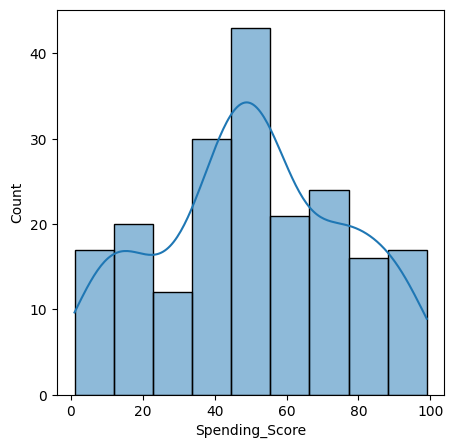

In [344]:
numerical_cols=['Age','Annual_Income','Spending_Score']

# for each col plot histplot with kde
for col in numerical_cols:
    plt.figure(figsize=(5,5))
    sns.histplot(data=df[col],kde=True)
    plt.show()

In [250]:
# age interpretation

# most customers are between 30 and 35 yrs
# then theres a bump between 40 and 45 showing significant no of customers in that age group followed by 30-35
# the distribution is right skewed(very few old aged visit mall) 
# age spans from approx 18 to 70

In [251]:
# annual income interpretation

# most earn between 60 to 80k$
# right skewed meaning very few earn more(more than 90k$)
# gradual inc from left and suuden tapering at right after 85 means most earn less than or equal to 80k$

In [252]:
# spending score interpretation

# trimodal distribution
# highest peak at middle meaning most cust have score approx 50
# then at 70
# then a smaller at 10

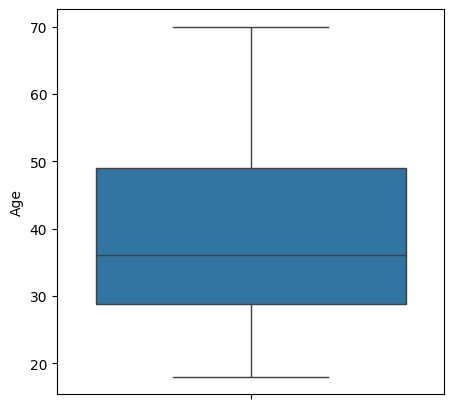

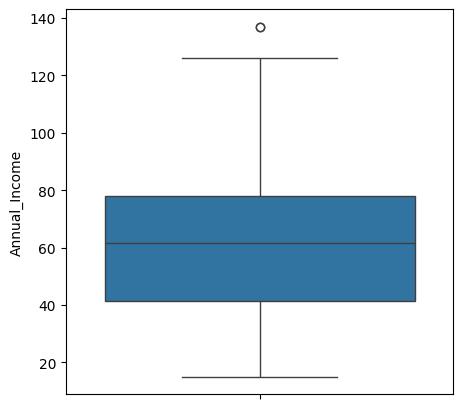

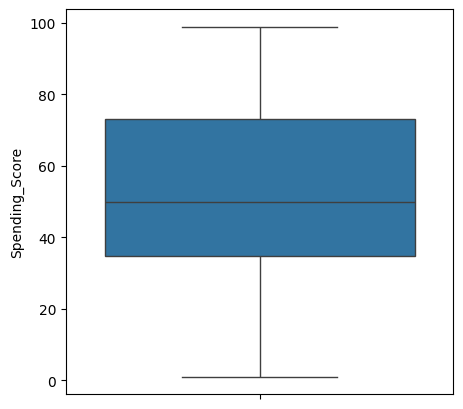

In [253]:
# plot boxplot for each numerical_col

for col in numerical_cols:
    plt.figure(figsize=(5,5))
    sns.boxplot(data=df[col])
    plt.show()

In [254]:
# remember the box height does not measure the number of customers
# like the entire box irrespective of how tall or short it is contains only 50% of customers
# Because each section of a boxplot (bottom whisker, lower half of box, upper half of box, top whisker) 
# always holds 25% of the customers, a narrower section simply means those 25% of customers are crowded closely together in value.

In [255]:
# age 
# 1. median age approx 35 yrs
# 2.50% customers lie in 30 to 50 yrs of age
# the median close to lower quartile means most values are concentrated there i.e near about 30


In [256]:
# annaul income
# median around 62k$
# the upper 25% are sparsely distributed between 80k$ to 120k$
# 50% customer earn between 42 to 80k$

In [257]:
# spending_score
# median is around 50
# pulled down because most people spending score is less than 50
# the upper 50% to 75% has customers spending scores sparsely spread from 50 to approx 76


### bivariate anaylsis

<Axes: xlabel='Age', ylabel='Annual_Income'>

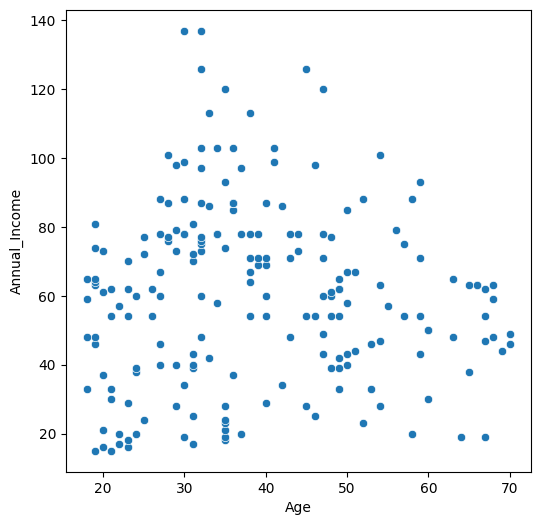

In [258]:
# age vs annual income

plt.figure(figsize=(6,6))
sns.scatterplot(data=df,x='Age',y='Annual_Income')


In [259]:
# no clear linear +ve or -ve relationship
# but an infer that high earners above 100k$ lie between 30 and 40 yrs of age mostly
# also most peole earn between 40 to 80k$ as seen by the number of dots appearing in that region across entire x axis (age axis)

In [260]:
df['Age'].corr(df['Annual_Income'])

np.float64(-0.012398042736060138)

In [261]:
# age and annual_income pearson correlation  --> Pearson correlation measures linear association (Spearman measures monotonic association)
# age and annual income have almost no linear association in this dataset as the value is -ve and very close to 0

# Correlation	    Interpretation
# Close to +1	   Strong positive linear relationship
# Close to -1	   Strong negative linear relationship
# Close to 0	   Weak or no linear relationship

<Axes: xlabel='Age', ylabel='Spending_Score'>

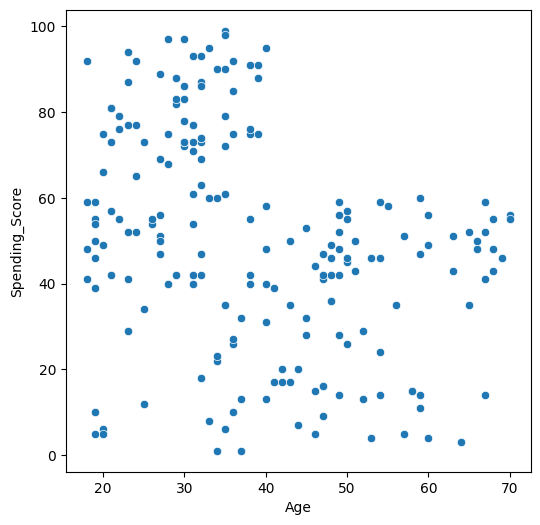

In [262]:
# age vs spending score

plt.figure(figsize=(6,6))

sns.scatterplot(data=df,x='Age',y='Spending_Score')

In [263]:
# again no clear linear relationship from the scatterplot can be seen
# one imp observation that can be derived is high spending scores above 60 are only seen for people under approx 42 yrs of age
# above 42 yrs of age people have moderate spending score around 60 or below
# meaning younger or old adults below 40 have highest spending scores whereas those who are 40+ have comparitively low spending scores

In [264]:
df['Age'].corr(df['Spending_Score'])

np.float64(-0.32722684603909)

In [265]:
# we see the relationship is much above -1 and less than 0
# this is linear -ve relationship which is still weak 

# Absolute_correlation	    Strength
# 0–0.19	                Very weak
# 0.20–0.39               	Weak
# 0.40–0.59	                Moderate
# 0.60–0.79	                Strong
# 0.80–1.00	                Very strong
# so as age inc the spending score dec

<Axes: xlabel='Annual_Income', ylabel='Spending_Score'>

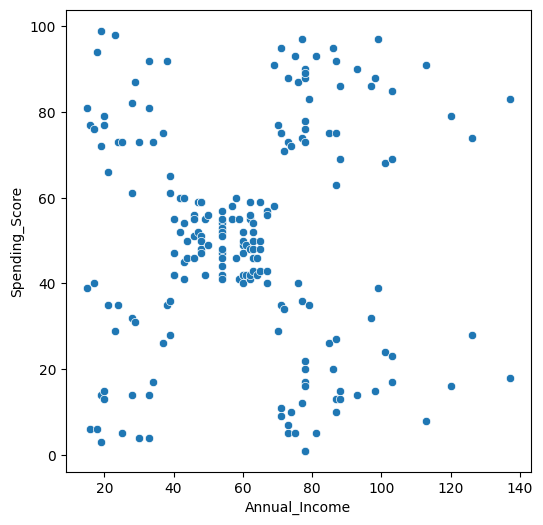

In [266]:
# annual income vs spending score

plt.figure(figsize=(6,6))

sns.scatterplot(data=df,x='Annual_Income',y='Spending_Score')

In [267]:
# no such linear relationship
# but the cluster of points makes it clear that the clusters of custoers can be formed based on relationship between these two features

# Conclusions
# 1.a lot of people earning betn 40-60k$ have spending score in same range 40-60
# 2.see left on x axis those having low annual income in them cant say if their scores are more or less as equal no of dots can be seen below on yaxis
# as well as above upwrads on y axis(spending score)
# 3.for those earning high see right on age axis i.e x axis however we can see the dots are slightly more in no upwards i.e high spending scores


In [268]:
df['Annual_Income'].corr(df['Spending_Score'])

np.float64(0.009902848094037606)

In [269]:
# we see the linear relationship is negligibly +ve
# so no clear linear relationship between annualincome and spending score

In [270]:
# summarizing bivariate analysis

# Feature pair	                 Pearson correlation	Observation
# Age – Annual Income	                 -0.0124	        Almost no linear relationship
# Age – Spending Score	            -0.3272	            Weak negative relationship
# Annual Income – Spending Score	     ~0.009	            Almost no linear relationship

### multivariate analysis

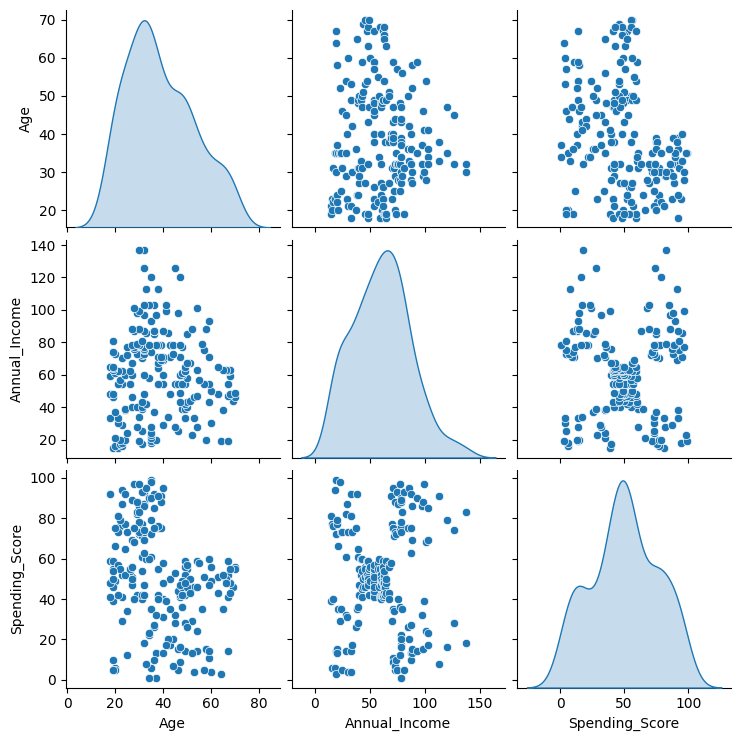

In [271]:
sns.pairplot(
    df,
    vars=['Age','Annual_Income','Spending_Score'],
    diag_kind='kde'
)

plt.show()

In [272]:
# Conclusioins


# 1. Individual Feature Distributions (Diagonal Plots)

# • Age. Smoothly right-skewed distribution peaking around 30 to 35 years old
# • Annual Income. Roughly bell-shaped around $60k to $75k, with a long right tail stretching out to high-income outliers near around 150k$.
# • Spending Score. Trimodal distribution with a strong central peak around 50 and two smaller side peaks

# 2. Annual Income vs. Spending Score (Strongest Clustering Pair)
# • Five Distinct Clusters. This pair forms 5 natural, non-overlapping groups aranged as cross
	# • Low Income, Low Spending ($15k–$40k income, 1–40 score).
	# • Low Income, High Spending ($15k–$40k income, 60–100 score).
	# • Medium Income, Medium Spending ($40k–$70k income, 40–60 score).
	# • High Income, Low Spending ($70k–$137k income, 1–40 score).
	# • High Income, High Spending ($70k–$137k income, 60–100 score).
# • No Linear Correlation. Knowing a customer's income alone does not linearly predict higher or lower spending—instead, 
# high earners split cleanly into either very frugal or very high spenders.

# 3. Age vs. Spending Score 
# • Strict Age Ceiling at 40 for High Spenders. Every customer with a Spending Score above 60 is between 18 and 40 years old—zero shoppers over 40 fall into the top spending tier.
# • Two Groups Above Age 40. Customers aged 40 to 70 split into moderate spenders (40–60 score) and low spenders (1–40 score).

# 4. Age vs. Annual Income (Weakest Separation)
# • No Distinct Clusters. Points scatter fairly evenly without forming clean islands.
# • Prime Earning Window. The highest earners ($90k–$137k) are mostly concentrated between 30 and 50 years old, while very young (18–25) and senior (60–70) visitors generally earn under $70k.

# 5. Overall Modeling Conclusion
# • Best Features to Start With. Annual Income and Spending Score provide the cleanest separation and point directly toward testing 5 clusters (\(k = 5\)) in K-Means.

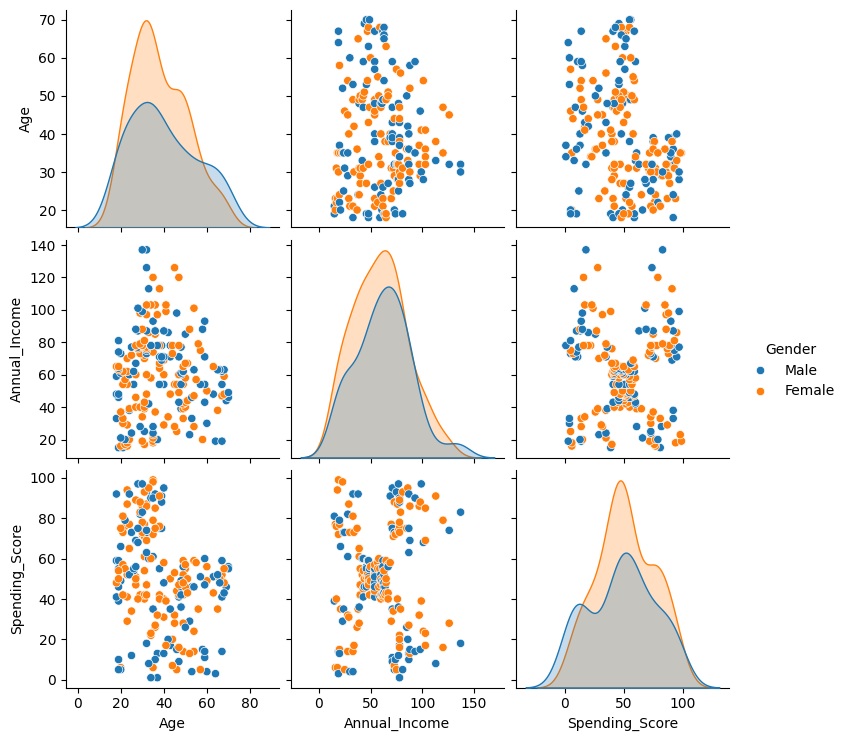

In [273]:
sns.pairplot(
    df,
    vars=['Age', 'Annual_Income', 'Spending_Score'],
    hue='Gender',
    diag_kind='kde'
)

plt.show()

In [274]:

# . Diagonal KDE Curves (Gender Distribution)

# • More Women Overall. The orange curve (Female) sits noticeably higher than the blue curve (Male) across all three diagonal plots, 
# showing there are more female shoppers than male shoppers in the dataset.
# • Same Peak Locations. Both curves peak at roughly the same horizontal positions across Age, Income, and Spending Score, 
# showing that men and women share similar typical values.
# • Slight Tail Differences. Men show a slightly higher bump in the low spending score region (near 0–20) and at the highest income extreme
# (above 120k), while women have a sharper peak in the middle spending range (around 50).


# 2. Annual Income vs. Spending Score

# • Complete Gender Overlap Across All 5 Clusters. Every one of the 5 distinct clusters contains a roughly even mix of blue (Male) and orange (Female) dots.
# • No Gender-Driven Segment. Neither men nor women form their own separate cluster or dominate any specific income-spending group.


# 3. Age vs. Spending Score

# • Same Age-40 Cutoff for Both Genders. Both male and female high spenders (spending score above 60) stay strictly under age 40.
# • Older Low Spenders. Above age 40, both men and women stay at or below a spending score of 60, with a slightly higher visible cluster of blue (Male) dots in the low-spending corner (below 20).


# 4. Age vs. Annual Income

# • Evenly Mixed Throughout. Male and female points overlap heavily across all ages and income levels with no visible separation.



In [275]:
# we see gender does not contribute much in cluster formation so keep it aside while clustering
# lets see with proper numbers

df.groupby('Gender')[['Age','Annual_Income','Spending_Score']].mean()

,Age,Annual_Income,Spending_Score
Gender,,,
Female,38.098214,59.250000,51.526786
Male,39.806818,62.227273,48.511364


In [276]:
# men slightly older on an avg
# men avg income slightly more
# women avg spending score more than men

In [277]:
df.groupby('Gender')[['Age', 'Annual_Income', 'Spending_Score']].median()

,Age,Annual_Income,Spending_Score
Gender,,,
Female,35.0,60.0,50.0
Male,37.0,62.5,50.0


In [278]:
# median male age is more
# median income of male is more
# median spending score same for both

In [279]:
# count of csuters by gender
df['Gender'].value_counts(normalize=True) * 100

Gender
Female    56.0
Male      44.0
Name: proportion, dtype: float64

In [280]:
# 56% female and 44% male

## FEATURE SELECTION

In [281]:
# CustomerID is identifier col it does not help in determing customer behaviour if we include in clustering its values will be used to
# calculate euclidian distance and create unneceassary complexities so exclude
# Age exclude in first model
# Annual_Income keep 
# Spending_Score keep

## PREPROCESSING

### Scaling


In [282]:
# scale age income and scores as all have diff range of values


In [283]:
from sklearn.preprocessing import StandardScaler

sc=StandardScaler()

# create the feature dataframe

X=df[['Age','Annual_Income','Spending_Score']] # X is a df

X_scaled=sc.fit_transform(X)

type(X_scaled)

# X_scaled

numpy.ndarray

In [284]:
# convert to df

X_scaled=pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled.head(5)

,Age,Annual_Income,Spending_Score
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## CLUSTERING

In [285]:
# need to find how many clusters we need
# note:here we know we need 5 from the data distribution still we find using elbow method

from sklearn.cluster import KMeans

# finding within cluster sum of squares for each value of k
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10) # for each k value run the kmeans algo
    # (i.e picking a centroid initially then assiging points to those ecntroids) 10 times
    # like for eg let say k=3 so that means we have to take 3 pts as centroids of 3 clusters initially then assign the points to their respective clusters
    # calculate their wcss 
    # this step do 10 times svery time take 3 random points as initial centroids then assign other points to them calculate wcss
    # then select the best wcss score for each k value from the 10 attempts
    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_) # for each k value the best wcss score append in the list wcss created above

In [286]:
wcss

[600.0,
 389.3861889564372,
 295.2122461555489,
 205.22514747675913,
 168.24758017556837,
 133.86842085478855,
 117.01155455889813,
 103.87329152383714,
 93.09289110041726,
 82.38515364526599]

In [287]:
# we see at k=5 the wcss score is 117 after that the dec is very slow
# still well plot a graph to see

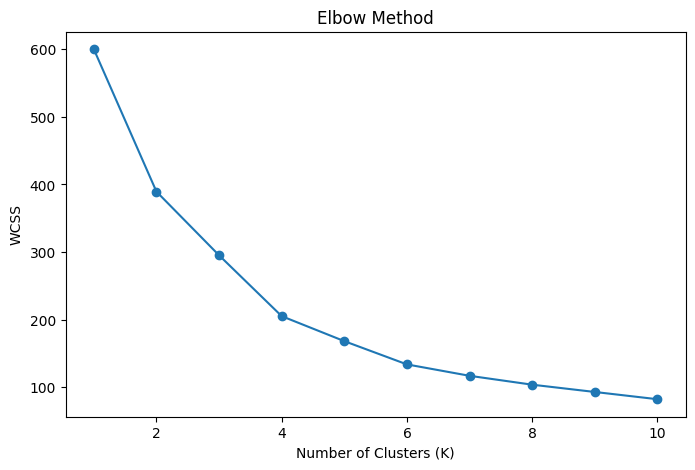

In [288]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')  # plot the line plot of k value(x axis) vs wcss score(y axis)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

In [289]:
# we see elbow is approx at 5

In [290]:
# now we will take clusters as 5 and fit the kmeans on our scaled data

kmeans=KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 3)","[[ 0.

In [291]:
# when km is fit on X_scaled first it finds the best initial set of starting 5 clsuter centroids and assigns points from X_scaled to them
# now points here are rows/records where each record/row is one customer data

In [292]:
kmeans.labels_
# each row or record is assigned a cluster label based on what cluster it is assigned to based on its min dist from that cluster
# labels are 0,1,2,3,4 for 5 clusters

array([1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 4, 1, 0, 1,
       0, 1, 4, 1, 1, 1, 4, 1, 1, 4, 4, 4, 4, 4, 1, 4, 4, 1, 4, 4, 4, 1,
       4, 4, 1, 1, 4, 4, 4, 4, 4, 1, 4, 4, 1, 4, 4, 1, 4, 4, 1, 4, 4, 1,
       1, 4, 4, 1, 4, 4, 1, 1, 4, 1, 4, 1, 1, 4, 4, 1, 4, 1, 4, 4, 4, 4,
       4, 1, 3, 1, 1, 1, 4, 4, 4, 4, 1, 3, 2, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 4, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2], dtype=int32)

In [293]:
# • WCSS is Used Inside n_init: Because the number of clusters (k) stays fixed across all 10 runs 
# (for example, all 10 runs use k = 5), comparing WCSS directly is completely fair. 
# Whichever of the 10 runs ends up with the lowest WCSS has the tightest, best-grouped clusters for that specific k.

In [294]:
# store this in df
df['cluster_labels']=kmeans.labels_

In [295]:
df.head(5)

,CustomerID,Gender,Age,Annual_Income,Spending_Score,cluster_labels
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1


In [296]:
# now we count how many points in each cluster

df['cluster_labels'].value_counts()

cluster_labels
1    54
4    47
2    40
3    39
0    20
Name: count, dtype: int64

In [297]:
# most points belong to cluster 1 and 4

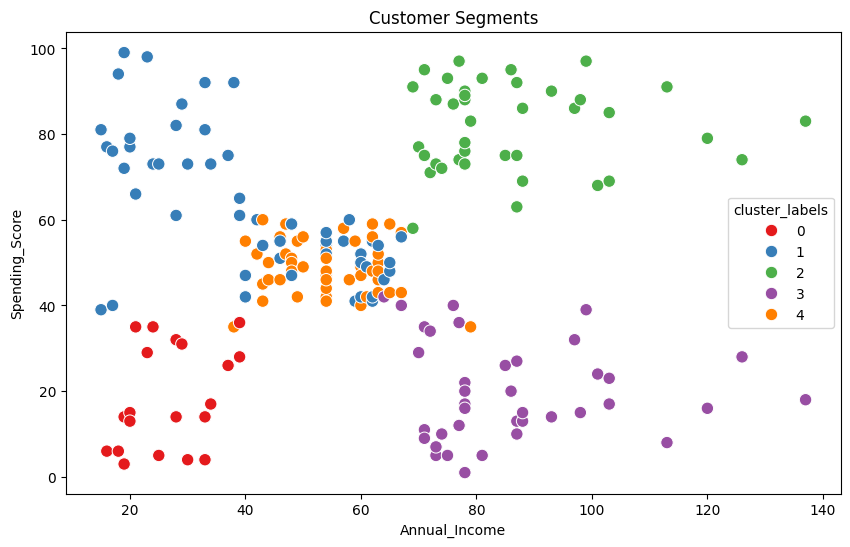

In [298]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income',
    y='Spending_Score',
    hue='cluster_labels',
    palette='Set1',
    s=80
)

plt.title('Customer Segments')
plt.show()

In [299]:
# we trained K-Means using Age, Income and Spending Score.
# The graph only displays Income and Spending Score. Age can therefore influence why certain customers belong to the same cluster.

In [300]:
# find avg of age income and spending scores for each cluster

df.groupby('cluster_labels')[['Age','Annual_Income','Spending_Score']].agg(['mean','median','max','min'])

Age                Annual_Income                  \
                     mean median max min          mean median  max min   
cluster_labels                                                           
0               46.250000   47.0  67  20     26.750000   26.5   39  16   
1               25.185185   24.0  38  18     41.092593   40.0   67  15   
2               32.875000   32.0  40  27     86.100000   78.5  137  69   
3               39.871795   41.0  59  19     86.102564   78.0  137  64   
4               55.638298   54.0  70  40     54.382979   54.0   79  38   

               Spending_Score                 
                         mean median max min  
cluster_labels                                
0                   18.350000   14.5  36   3  
1                   62.240741   58.0  99  39  
2                   81.525000   83.0  97  58  
3                   19.358974   17.0  42   1  
4                   48.851064   48.0  60  35

In [301]:
# Cluster 0 — Low-value spending segment
# - Lowest average income and spending score.
# - Customers are relatively older.
# - They may have limited purchasing power or lower engagement with the mall.
# Cluster 1 — Young, active customers
# - Youngest group.
# - Moderate income but relatively high spending.
# - Potentially valuable customers for promotions and engagement campaigns.
# Cluster 2 — High-value customers
# - High average income.
# - Highest average spending score.
# - An important segment for premium products, loyalty programmes and exclusive offers.
# Cluster 3 — High-income, low-spending customers
# - Average income is almost identical to Cluster 2.
# - However, their average spending score is dramatically lower.
# - This is particularly interesting: having a high income does not necessarily mean a customer spends more at the mall.
# Cluster 4 — Older, moderate-spending customers
# - Oldest group.
# - Moderate income and spending.
# - Could respond to products and promotions suited to their preferences.

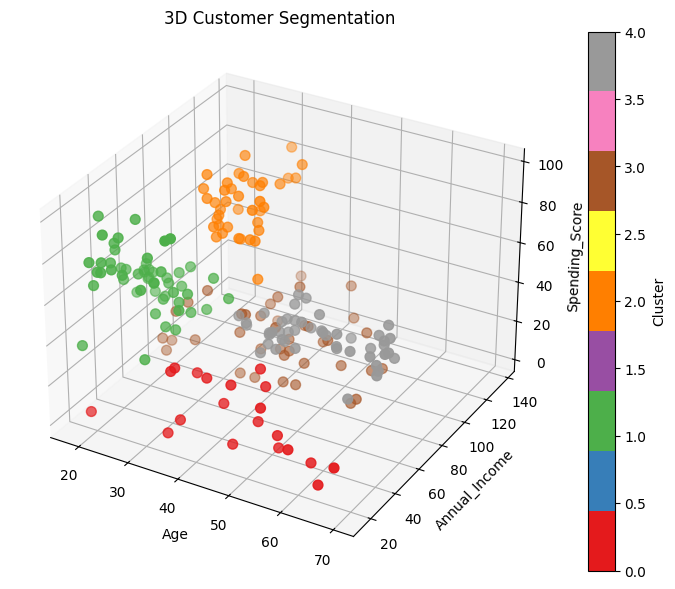

In [302]:
# now lets visualize for each cluster the age , income and spending scores

fig=plt.figure(figsize=(10,7))  # a blank canvas

ax=fig.add_subplot(111,projection='3d')  # create grid on the canvas 
# 111 means 1 row 1 col and 1 is plot1 (i.e this 1 plot will take up entire grid space of ax)

scatterplot=ax.scatter(
    df['Age'],  # x axis
    df['Annual_Income'],  # y axis
    df['Spending_Score'],  # z axis
    c=df['cluster_labels'],  # color or hue based on cluster labels
    cmap='Set1', # color
    s=50 # size

)

ax.set_xlabel('Age')
ax.set_ylabel('Annual_Income')
ax.set_zlabel('Spending_Score')

ax.set_title('3D Customer Segmentation')

plt.colorbar(scatterplot, label='Cluster')
plt.show()



In [303]:
# not clear enough so use plotly

import plotly.express as px

fig = px.scatter_3d(
    df,
    x='Annual_Income',
    y='Spending_Score',
    z='Age',
    color='cluster_labels',
    hover_data=['CustomerID', 'Gender'],
    title='Customer Segmentation - 3D Cluster Visualization',
    opacity=0.75
)

fig.update_traces(marker=dict(size=5))

fig.update_layout(
    width=1000,
    height=750,
    scene=dict(
        xaxis_title='Annual Income',
        yaxis_title='Spending Score',
        zaxis_title='Age'
    )
)

fig.show()

In [304]:
# need centroids also

centroids = sc.inverse_transform(kmeans.cluster_centers_)  # centroids were calculated based on scaled data as kmeans was applied on X_scaled
# we want them back in oridinal units so use inverse_transform


# centroids
centroid_df = pd.DataFrame(
    centroids,
    columns=['Age', 'Annual_Income', 'Spending_Score']
)

centroid_df['cluster_labels'] = range(5)

centroid_df

,Age,Annual_Income,Spending_Score,cluster_labels
0,46.250000,26.750000,18.350000,0
1,25.185185,41.092593,62.240741,1
2,32.875000,86.100000,81.525000,2
3,39.871795,86.102564,19.358974,3
4,55.638298,54.382979,48.851064,4


In [305]:
# for cluster 0 the centroid is (46.250000,26.750000,18.350000)
# for cluster 1 the centroid is (25.185185,41.092593,62.240741)
# and so on

In [345]:
fig.add_scatter3d(
    x=centroid_df['Annual_Income'],
    y=centroid_df['Spending_Score'],
    z=centroid_df['Age'],
    mode='markers',
    marker=dict(
        size=7,
        color='black',
        symbol='x',
        line=dict(width=3)
    ),
    name='Centroids'
)

fig.show()

AttributeError: 'Figure' object has no attribute 'add_scatter3d'

In [307]:
# evaulate silhoutte score
# silhoutte score is dist of every point from all other points in its cluster as compared to points in other nearest cluster
# close to +1 means cluster is well seperated
# close to -1 means not well seperated
# close to 0 means point lies on boundary of the two clusters

from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, kmeans.labels_) # kmeans.labels_ is the cluster labels (0,1,2,3,4)

print("Silhouette Score:", score)

Silhouette Score: 0.41664341513732767


In [308]:
# find silhoutte scores for diff k values to determine if selected k value is actually that optimal

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    km = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = km.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3355
K = 3, Silhouette Score = 0.3578
K = 4, Silhouette Score = 0.4040
K = 5, Silhouette Score = 0.4166
K = 6, Silhouette Score = 0.4284
K = 7, Silhouette Score = 0.4172
K = 8, Silhouette Score = 0.4082
K = 9, Silhouette Score = 0.4177
K = 10, Silhouette Score = 0.4066


In [309]:
# max seperation obtained for k=6
# higher score indicates better cohesion(how close to points of same cluster) and seperation(how far from points of nearest cluster)

In [187]:
# the diff between silhoutte of k=5 and 6 is very small 
# evaluate by fitting on k=6 and then see

kmeans_6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)  

labels_6 = kmeans_6.fit_predict(X_scaled)  # the cluster labels of each recors/row/customer  are stored 
# fit identifies the best 6 centroids to which when points are assigned the wcss score is min by taking 10 diff starting combinations of centroids
# predict finally assigns the scaled points (each row or record of X_scaled is age,income,spending score scaled and each row is one point) to the best centroids found

print(pd.Series(labels_6).value_counts().sort_index())
print(df['cluster_labels'].value_counts().sort_index())

0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64
cluster_labels
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64


In [310]:
# we see diff now lets see on the plot

from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    subplot_titles=('K = 5 Clusters', 'K = 6 Clusters')
)

# K = 5
for cluster in sorted(df['cluster_labels'].unique()):
    data = df[df['cluster_labels'] == cluster]

    fig.add_trace(
        go.Scatter3d(
            x=data['Annual_Income'],
            y=data['Spending_Score'],
            z=data['Age'],
            mode='markers',
            name=f'Cluster {cluster}',
            legendgroup=f'k5_{cluster}',
            showlegend=False,
            marker=dict(size=4),
            hovertext=data['CustomerID']
        ),
        row=1, col=1
    )

# K = 6
df_6 = df.copy()
df_6['cluster_labels'] = labels_6

for cluster in sorted(df_6['cluster_labels'].unique()):
    data = df_6[df_6['cluster_labels'] == cluster]

    fig.add_trace(
        go.Scatter3d(
            x=data['Annual_Income'],
            y=data['Spending_Score'],
            z=data['Age'],
            mode='markers',
            name=f'Cluster {cluster}',
            legendgroup=f'k6_{cluster}',
            showlegend=False,
            marker=dict(size=4),
            hovertext=data['CustomerID']
        ),
        row=1, col=2
    )

fig.update_layout(
    title='Customer Segmentation: K=5 vs K=6',
    width=1200,
    height=650
)

fig.show()

In [311]:
print("K = 5 CLUSTER STATISTICS")

stats_5 = df.groupby('cluster_labels')[
    ['Age', 'Annual_Income', 'Spending_Score']
].agg(['mean', 'median', 'std', 'min', 'max', 'count'])

display(stats_5.round(2))


print("K = 6 CLUSTER STATISTICS")

stats_6 = df_6.groupby('cluster_labels')[
    ['Age', 'Annual_Income', 'Spending_Score']
].agg(['mean', 'median', 'std', 'min', 'max', 'count'])

display(stats_6.round(2))

K = 5 CLUSTER STATISTICS


Age                             Annual_Income                \
                 mean median    std min max count          mean median    std   
cluster_labels                                                                  
0               46.25   47.0  11.58  20  67    20         26.75   26.5   7.31   
1               25.19   24.0   5.51  18  38    54         41.09   40.0  16.82   
2               32.88   32.0   3.86  27  40    40         86.10   78.5  16.34   
3               39.87   41.0  10.94  19  59    39         86.10   78.0  16.73   
4               55.64   54.0   8.91  40  70    47         54.38   54.0   8.82   

                              Spending_Score                              
               min  max count           mean median    std min max count  
cluster_labels                                                            
0               16   39    20          18.35   14.5  11.94   3  36    20  
1               15   67    54          62.24   58.0  16.60  39  99    54  
2               69  137    40          81.53   83.0  10.00  58  97    40  
3               64  137    39          19.36   17.0  11.61   1  42    39  
4               38   79    47          48.85   48.0   6.30  35  60    47

K = 6 CLUSTER STATISTICS


Age                             Annual_Income                \
                 mean median    std min max count          mean median    std   
cluster_labels                                                                  
0               56.33   54.0   8.45  43  70    45         54.27   54.0   8.98   
1               26.79   26.0   7.06  18  40    39         57.10   60.0  10.16   
2               41.94   43.0  10.18  19  59    33         88.94   86.0  16.59   
3               32.69   32.0   3.73  27  40    39         86.54   79.0  16.31   
4               25.00   23.0   5.30  18  35    23         25.26   24.0   7.72   
5               45.52   46.0  11.77  20  67    21         26.29   25.0   7.44   

                              Spending_Score                              
               min  max count           mean median    std min max count  
cluster_labels                                                            
0               38   79    45          49.07   49.0   6.30  35  60    45  
1               39   76    39          48.13   50.0   9.97  10  61    39  
2               71  137    33          16.97   16.0   9.96   1  39    33  
3               69  137    39          82.13   83.0   9.36  63  97    39  
4               15   39    23          77.61   77.0  13.27  39  99    23  
5               16   39    21          19.38   15.0  12.56   3  40    21

In [312]:
# from this cant conclude if some useful cluster was created or not

In [313]:
comparison = pd.crosstab(
    df['cluster_labels'],
    df_6['cluster_labels']
)

display(comparison)

cluster_labels,0,1,2,3,4,5
cluster_labels,,,,,,
0,0,0,0,0,0,20
1,0,30,0,0,23,1
2,0,1,0,39,0,0
3,0,6,33,0,0,0
4,45,2,0,0,0,0


In [314]:
# cluster0 of k=5 had 20 cust that went into cluster5 of k=6
# cluster1 of k=5 had 54 cust that went as follows 30 to cluster1,23 to cluster4,1 to cluster5 of k=6

In [315]:
# we see in k=6
# cluster1 and cluster 4 have same age but the avg income and the spending scores differ
# this is useful segregation

In [316]:
# decide

# we see silhoutte score for k=6 is higher than k=5 means the cohesion and seperation is better i.e clusters are better formed
# not only this but the k=6 also finds a cust segment with same age but diff incomes and spending scores thereby identifying an
# additional customer segment than k=5

# so select k=6 (based on evidences discussed here)

In [317]:
df_final = df.copy()

df_final['cluster_labels'] = labels_6

df_final['cluster_labels'].value_counts().sort_index()

cluster_labels
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

In [318]:
# cluster profiles --> summary describing the typical customer in each cluster

df_final.groupby('cluster_labels')[['Age','Annual_Income','Spending_Score']].agg(['mean','median','count'])

Age              Annual_Income               \
                     mean median count          mean median count   
cluster_labels                                                      
0               56.333333   54.0    45     54.266667   54.0    45   
1               26.794872   26.0    39     57.102564   60.0    39   
2               41.939394   43.0    33     88.939394   86.0    33   
3               32.692308   32.0    39     86.538462   79.0    39   
4               25.000000   23.0    23     25.260870   24.0    23   
5               45.523810   46.0    21     26.285714   25.0    21   

               Spending_Score               
                         mean median count  
cluster_labels                              
0                   49.066667   49.0    45  
1                   48.128205   50.0    39  
2                   16.969697   16.0    33  
3                   82.128205   83.0    39  
4                   77.608696   77.0    23  
5                   19.380952   15.0    21

In [319]:
# Cluster	 Age	Income	Spending	Customer profile
# 0	        56	      54	  49	     Older, moderate income, moderate spending
# 1	        27	      57	  48	     Young, moderate income, moderate spending
# 2	        42	      89	  17	      Middle-aged, high income, low spending
# 3	        33	      87	  82	       Young, high income, high spending
# 4	        25	      25	  78	        Young, low income, high spending
# 5	        46	      26	  19	         Middle-aged, low income, low spending

In [320]:
# visualize cluster profiles

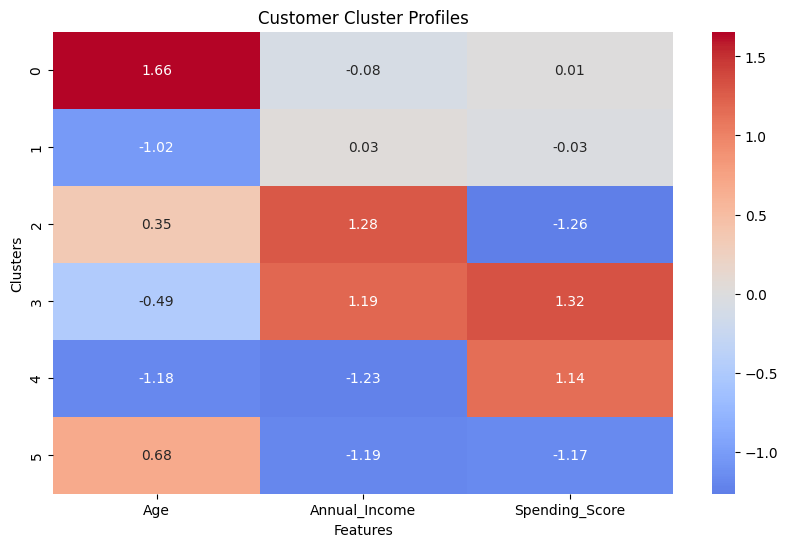

In [321]:


# Calculate mean values for each cluster
cluster_means = df_final.groupby('cluster_labels')[['Age','Annual_Income','Spending_Score']].mean()  # cluster_means is a df


# Standardize the cluster means
sc_cluster = StandardScaler()

cluster_means_scaled = pd.DataFrame(
    sc_cluster.fit_transform(cluster_means),
    columns=['Age','Annual_Income','Spending_Score'],
    index=cluster_means.index
)

# Plot heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_means_scaled,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Customer Cluster Profiles')
plt.xlabel('Features')
plt.ylabel('Clusters')
plt.show()

In [322]:
# average age of cluster 0 is the max as seen by the red color and +ve value
# average annual income is max for cluster 2 as seen from orange color and +ve val
# average spending score is max for cluster 3 as seen from orange color and +ve val

# Positive value: That cluster's average is above the average across all six cluster means for that feature.
# Negative value: It is below that average.
# Near zero: It is close to that average.

# a high +ve value for any cluster for any feature means for that feature the avg value of that cluster is much greater than the avg value of that feature
# for other clusters
# eg see for age for cluster 0 the avg value is 1.66 much higher than others avg values

# the heatmap just ranks each feature avg value for each cluster

# eg for age max avg val of age goes as C0,C5,C2,C3,C1,C4


In [323]:
# business insights

# cluster_summary is a df with cols Customer_count,Avg_age,Avg_Income,Avg_spending
cluster_summary = df_final.groupby('cluster_labels').agg(
    Customer_Count=('cluster_labels', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Annual_Income', 'mean'),
    Avg_Spending=('Spending_Score', 'mean')
).round(2)

cluster_summary

,Customer_Count,Avg_Age,Avg_Income,Avg_Spending
cluster_labels,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


In [324]:
# cluster 0 Older customers, moderate income, moderate spending. Largest segment (45 customers).
# cluster 1 Young customers, moderate income, moderate spending.
# cluster 2 Middle-aged customers, high income, low spending.
# cluster 3 Young customers, high income, high spending.
# cluster 4 Young customers, low income, high spending.
# cluster 5 Middle-aged customers, low income, low spending.

In [325]:
# recommendations

# Cluster      	Customer profile	                                Possible business strategy
# 0	           Older, moderate income, moderate spending	        General promotions, loyalty programmes and convenience-focused offers
# 1	           Young, moderate income, moderate spending	         Student/young-adult offers, seasonal discounts and trend-based products
# 2	           Middle-aged, high income, low spending	              Understand what prevents spending; targeted offers and personalized recommendations
# 3	           Young, high income, high spending	                  Premium products, exclusive collections and loyalty rewards
# 4	           Young, low income, high spending	                      Affordable trendy products, bundles and discounts
# 5	           Middle-aged, low income, low spending	               Value-for-money products, essential items and budget offers

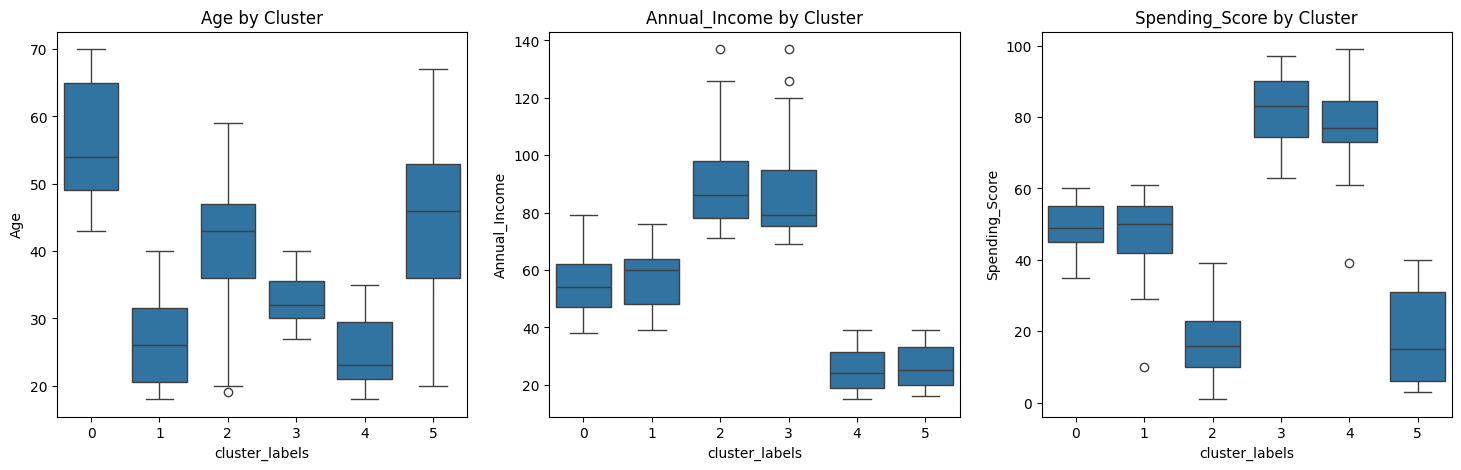

In [346]:
# now we investigate each cluster not on mean basis but check distribution of each feature in each cluster

fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 row and 3 cols

for i, feature in enumerate(['Age','Annual_Income','Spending_Score']):
    sns.boxplot(
        data=df_final,
        x='cluster_labels',
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f'{feature} by Cluster')

# plt.tight_layout()
plt.show()

In [327]:
# for age

# we see customers in cluster 2 and cluster 5 have more spread out ages
# we know cluster 5 has very few customers (21) but the age of each is varied as seen by the long box plot going from approx 20 till approx 65-68
# cluster 3 which conatins young cust with high income and high spending has all customers in very small age range as seen from the small boxplot going from approx 26 to approx 40
# avg age of cust in cluster 1 and cluster 4 is very close as seen again in boxplot

In [328]:
# for annual_income
# cluster 0 and 1 seem to have identical distribution
# cluster 2 and 3 same near about identical distribution 
# cluster 4 and 5 also same
# there are some outliers in 2 and 3 which are high spneding ones

In [329]:
# spending score
# for cluster 0 and 1 its nearbout similar 
# for cluster 2 and 5 its similar
# for cluster 3 and 4 its similar


In [330]:
# silhoutte score for each sample/record/roe/customet

from sklearn.metrics import silhouette_samples

silhouette_values = silhouette_samples(
    X_scaled, # contains scaled age,income,spending score for each cust
    labels_6 # array containing cluster label assigned to each cust in X_scaled
)

df_final['Silhouette_Score'] = silhouette_values

In [331]:
df_final

,CustomerID,Gender,Age,Annual_Income,Spending_Score,cluster_labels,Silhouette_Score
0,1,Male,19,15,39,4,0.056428
1,2,Male,21,15,81,4,0.636806
2,3,Female,20,16,6,5,0.111117
3,4,Female,23,16,77,4,0.647313
4,5,Female,31,17,40,5,0.036099
...,...,...,...,...,...,...,...
195,196,Female,35,120,79,3,0.484551
196,197,Female,45,126,28,2,0.372478
197,198,Male,32,126,74,3,0.416387
198,199,Male,32,137,18,2,0.317818


In [332]:
# now for each cluster find the avg silhoutte score

df_final.groupby('cluster_labels')['Silhouette_Score'].mean()

cluster_labels
0    0.490901
1    0.387324
2    0.331307
3    0.505195
4    0.507544
5    0.294187
Name: Silhouette_Score, dtype: float64

In [333]:
# checking parameters

# • Close to +1 (e.g., 0.50 to 0.85): The customer sits deep inside their assigned cluster and is far away from neighboring clusters. This is a rock-solid assignment.
# • Close to 0 (e.g., -0.05 to 0.15): The customer sits right on the boundary between two clusters and could almost belong to either one.
# • Negative (e.g., -0.01 to -0.50): The customer is actually closer to a neighboring cluster than to their own, meaning they are likely misclassified or an outlier.


# Cluster	   Average silhouette	Interpretation
# 0	               0.491	      Reasonably well separated
# 1	               0.387	       Moderate separation
# 2	               0.331	      Relatively weak separation
# 3	               0.505	       Good separation
# 4	               0.508	     Good separation
# 5	               0.294 	     Weakest separation

In [334]:
# now we will see hierarchial clustering approach called agglomerative clustering

from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=6,
    linkage='ward',
    metric='euclidean'
)

hc_labels = hc.fit_predict(X_scaled)

df_final['HC_cluster_labels'] = hc_labels

In [335]:
df_final

,CustomerID,Gender,Age,Annual_Income,Spending_Score,cluster_labels,Silhouette_Score,HC_cluster_labels
0,1,Male,19,15,39,4,0.056428,4
1,2,Male,21,15,81,4,0.636806,5
2,3,Female,20,16,6,5,0.111117,4
3,4,Female,23,16,77,4,0.647313,5
4,5,Female,31,17,40,5,0.036099,4
...,...,...,...,...,...,...,...,...
195,196,Female,35,120,79,3,0.484551,2
196,197,Female,45,126,28,2,0.372478,3
197,198,Male,32,126,74,3,0.416387,2
198,199,Male,32,137,18,2,0.317818,3


In [336]:
# find no of cust assigned to each cluster by hc

print(df_final['HC_cluster_labels'].value_counts().sort_index())
print(df_final['cluster_labels'].value_counts().sort_index())


HC_cluster_labels
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64
cluster_labels
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


In [337]:
pd.crosstab(
    df_final['cluster_labels'],
    df_final['HC_cluster_labels']
)

HC_cluster_labels,0,1,2,3,4,5
cluster_labels,,,,,,
0,2,43,0,0,0,0
1,39,0,0,0,0,0
2,3,2,0,28,0,0
3,0,0,39,0,0,0
4,1,0,0,0,1,21
5,0,0,0,0,21,0


In [338]:
# cluter 0 had 45 customers according to kmeans those get divided into cluster 0 and cluster 1 of Hierarchial clustering
# we see its not necessary that cluster labels in both are idnetical so their data or points should be identical too
# also kmeans light label low income low speending as 0 whereas hierarchial may label it as 1 so dont go by cluster labels also even if cluster labels 
# in both are same the data points may be different

# above conclusions
# cluster 0 of kmeans had 45 cust that get divided into clust 0 and clust 1 of hierarchial (means points in c0 of kmeans have moved to c1 of hierarchial)
# also cluster 1 of kmeans had 39 cust they moved to cluster 0 of HC
# also c2 in kmeans had 33 cust most moved to c4 of HC

# so even if labels are same points(customers belonging to that cluster) can be diff in both kmeans and HC

In [339]:
# now check silhoutte score to check how well the clusters are seperated in HC


hc_silhouette = silhouette_score(
    X_scaled,
    hc_labels
)

print("K-Means:", silhouette_score(X_scaled, labels_6))
print("Hierarchical:", hc_silhouette)

K-Means: 0.4284167762892593
Hierarchical: 0.4201169558789579


In [340]:
# for hierarchial the overall silhoutte is a bit less than kmeans

# for this kmeans is a better choice
# 1.it has higher silhoutte score
# 2.properly segments cust as low income low spending,high income high spending etc
# 3.it is computationally faster
# 4.can use predict() method to assign a new cust to any of the cluster that is not possible in agglomerative HC

In [341]:
### PIPELINE

In [347]:
from sklearn.pipeline import Pipeline

pip_scaler=StandardScaler()

X_scaled_1=pip_scaler.fit_transform(X) # fit means learn mean and SD and transform all the features(AGe,Income,Spending) to have mean 0 and SD1

pipeline=Pipeline(
    [
        ('scaler',pip_scaler),
        ('kmeans',kmeans_6)
    ]
)

pipeline_labels=pipeline.predict(df_final[['Age','Annual_Income','Spending_Score']])  # pass a df to predict function of pipeline
# scales the values in all the cols
# pass scaled data to means that assigns clusters to each cust and returns labels

print(pipeline_labels[:20])
print(labels_6[:20])
# we checked pipeline assign same labels

print("All predictions match:",
      (pipeline_labels == labels_6).all())








[4 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4]
[4 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4 5 4]
All predictions match: True


C:\Users\sanik\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


### saving final model

In [348]:
import joblib

joblib.dump(pipeline, 'customer_segmentation_model.pkl')

['customer_segmentation_model.pkl']

In [352]:
loaded_model = joblib.load('customer_segmentation_model.pkl')

# joblib.load() reads the saved file.
# loaded_model now contains the complete fitted pipeline
# It retains both the scaler and K-Means model.

loaded_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('kmeans', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Age','Annual_Income','Spending_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [354]:
# now pass new cust data to pieline and get its predicted cluster result

new_cust=pd.DataFrame({
    'Age':[30],  # new_cust is a df age,income are features so pass values in array[]
    'Annual_Income':[60],
    'Spending_Score':[60]
})

new_cust

,Age,Annual_Income,Spending_Score
0,30,60,60


In [356]:
assigned_cluster=loaded_model.predict(new_cust)

# loaded_model is a pipeline 
# 1.first scaler will scale all the values
# 2.then kmeans will run and cluster will be assigned

assigned_cluster[0]

C:\Users\sanik\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


np.int32(1)

In [381]:
# prediction function that not just returns cluster no but also the type of customer that belongs to that cluster

# def predict_customer_cluster(age, income, spending_score):

#     customer = pd.DataFrame({
#         'Age': [age],
#         'Annual_Income': [income],
#         'Spending_Score': [spending_score]
#     })

#     cluster = loaded_model.predict(customer)

#     return cluster[0]

customer_type={
    0: "Older - Moderate Income, Moderate Spending",
    1: "Young - Moderate Income, Moderate Spending",
    2: "Middle-aged - High Income, Low Spending",
    3: "Young - High Income, High Spending",
    4: "Young - Low Income, High Spending",
    5: "Middle-aged - Low Income, Low Spending"
}

def predict_customer_cluster(age,income,spending_score):
    # create df
    cust=pd.DataFrame({
        'Age':[age],
        'Annual_Income':[income],
        'Spending_Score':[spending_score]
    })

    assigned_cluster=loaded_model.predict(cust)

    return{
        'Cluster':assigned_cluster[0],
        'Type_of_customer':customer_type[assigned_cluster[0]]
    }

In [382]:
predict_customer_cluster(25,40,50)

C:\Users\sanik\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


{'Cluster': np.int32(1),
 'Type_of_customer': 'Young - Moderate Income, Moderate Spending'}